In [ ]:
# ==========================================
# 0. SETUP & REPRODUCIBILITY (ล็อก Random Seed)
# ==========================================
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# ==========================================
# 1. DATA PREPARATION (Fashion-MNIST)
# ==========================================
# Regularization ด้วย Data Augmentation
train_transform = transforms.Compose([
    transforms.RandomCrop(28, padding=2),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize((0.2860,), (0.3530,)) # สถิติ mean, std ของ Fashion-MNIST
])

test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.2860,), (0.3530,))
])

#Raw Data
full_train_dataset = datasets.FashionMNIST(root='./data', train=True, download=True, transform=train_transform)
test_dataset = datasets.FashionMNIST(root='./data', train=False, download=True, transform=test_transform)

#แยก Train (50,000) และ Val (10,000)
train_set, val_set = random_split(full_train_dataset, [50000, 10000], generator=torch.Generator().manual_seed(SEED))

train_loader = DataLoader(train_set, batch_size=64, shuffle=True)
val_loader = DataLoader(val_set, batch_size=64, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

classes = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
           'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

# ==========================================
# 2. MODEL ARCHITECTURE (Custom CNN)
# ==========================================

class FashionCNN(nn.Module):
    def __init__(self):
        super(FashionCNN, self).__init__()
        self.features = nn.Sequential(

            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),


            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.3), # Regularization
            nn.Linear(32 * 7 * 7, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 10) # 10 Classes logits
        )

    def forward(self, x):
        return self.classifier(self.features(x))

model = FashionCNN().to(device)

# ==========================================
# 3. LOSS & OPTIMIZER
# ==========================================
criterion = nn.CrossEntropyLoss() #จ่าย raw logits เข้าฟังก์ชันนี้โดยตรง
optimizer = optim.Adam(model.parameters(), lr=0.001)

# ==========================================
# 4. TRAINING & EVALUATION LOOP
# ==========================================
epochs = 10
history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

for epoch in range(epochs):
    # Train Mode
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for x_batch, y_batch in train_loader:
        x_batch, y_batch = x_batch.to(device), y_batch.to(device)

        optimizer.zero_grad()
        outputs = model(x_batch)
        loss = criterion(outputs, y_batch)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * x_batch.size(0)
        _, preds = torch.max(outputs, 1)
        correct += (preds == y_batch).sum().item()
        total += y_batch.size(0)

    train_loss = running_loss / total
    train_acc = correct / total

    # Eval Mode
    model.eval()
    val_loss, val_correct, val_total = 0.0, 0, 0
    with torch.no_grad():
        for x_val, y_val in val_loader:
            x_val, y_val = x_val.to(device), y_val.to(device)
            val_out = model(x_val)
            v_loss = criterion(val_out, y_val)

            val_loss += v_loss.item() * x_val.size(0)
            _, v_preds = torch.max(val_out, 1)
            val_correct += (v_preds == y_val).sum().item()
            val_total += y_val.size(0)

    val_loss = val_loss / val_total
    val_acc = val_correct / val_total

    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['train_acc'].append(train_acc)
    history['val_acc'].append(val_acc)

    print(f"Epoch [{epoch+1}/{epochs}] | Train Loss: {train_loss:.4f} Acc: {train_acc:.4f} | Val Loss: {val_loss:.4f} Acc: {val_acc:.4f}")

# บันทึก Model Weights
torch.save(model.state_dict(), "fashion_cnn.pth")

Using device: cuda


100%|██████████| 26.4M/26.4M [00:01<00:00, 13.4MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 202kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.72MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 23.7MB/s]


Epoch [1/10] | Train Loss: 0.6483 Acc: 0.7582 | Val Loss: 0.4482 Acc: 0.8346
Epoch [2/10] | Train Loss: 0.4803 Acc: 0.8197 | Val Loss: 0.4063 Acc: 0.8482
Epoch [3/10] | Train Loss: 0.4365 Acc: 0.8392 | Val Loss: 0.3766 Acc: 0.8592
Epoch [4/10] | Train Loss: 0.4160 Acc: 0.8465 | Val Loss: 0.3406 Acc: 0.8744
Epoch [5/10] | Train Loss: 0.3950 Acc: 0.8534 | Val Loss: 0.3532 Acc: 0.8711
Epoch [6/10] | Train Loss: 0.3796 Acc: 0.8608 | Val Loss: 0.3295 Acc: 0.8777
Epoch [7/10] | Train Loss: 0.3653 Acc: 0.8664 | Val Loss: 0.3194 Acc: 0.8809
Epoch [8/10] | Train Loss: 0.3552 Acc: 0.8690 | Val Loss: 0.3090 Acc: 0.8889
Epoch [9/10] | Train Loss: 0.3518 Acc: 0.8728 | Val Loss: 0.2925 Acc: 0.8937
Epoch [10/10] | Train Loss: 0.3427 Acc: 0.8748 | Val Loss: 0.2888 Acc: 0.8957


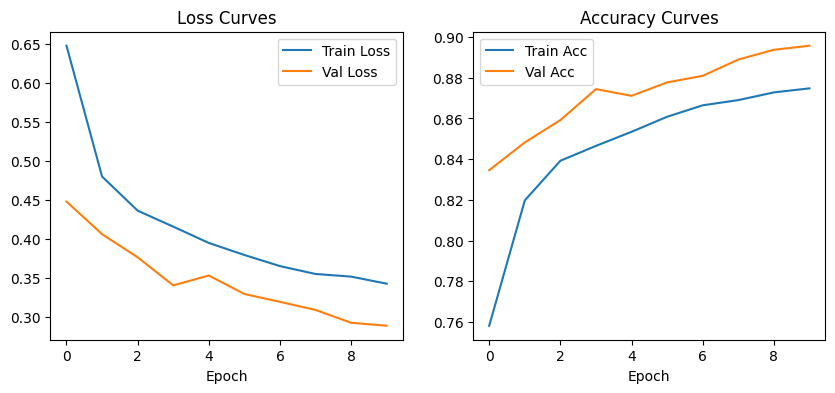

Final Test Accuracy: 90.11%


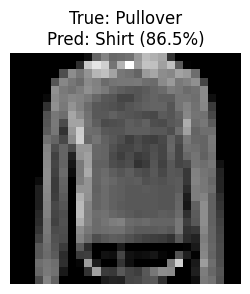

Failure Case: รูปจริงคือ 'Pullover' แต่โมเดลคิดว่าเป็น 'Shirt'


In [ ]:
# 1. พล็อต Learning Curves
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(history['train_loss'], label='Train Loss')
plt.plot(history['val_loss'], label='Val Loss')
plt.title('Loss Curves')
plt.xlabel('Epoch')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history['train_acc'], label='Train Acc')
plt.plot(history['val_acc'], label='Val Acc')
plt.title('Accuracy Curves')
plt.xlabel('Epoch')
plt.legend()
plt.savefig("learning_curves.png")
plt.show()

# 2. Test Set Evaluation
model.eval()
test_correct, test_total = 0, 0
failures = []

with torch.no_grad():
    for x_t, y_t in test_loader:
        x_t, y_t = x_t.to(device), y_t.to(device)
        out = model(x_t)
        probs = torch.softmax(out, dim=-1)
        _, preds = torch.max(out, 1)

        test_correct += (preds == y_t).sum().item()
        test_total += y_t.size(0)

        # เก็บเคสที่ผิด
        for i in range(len(y_t)):
            if preds[i] != y_t[i]:
                failures.append({
                    'img': x_t[i].cpu(),
                    'true': y_t[i].item(),
                    'pred': preds[i].item(),
                    'conf': probs[i][preds[i]].item()
                })

test_accuracy = test_correct / test_total
print(f"Final Test Accuracy: {test_accuracy * 100:.2f}%")

#3.โชว์ Honest Failure Case
if failures:
    fail = failures[0]
    plt.figure(figsize=(3, 3))
    # Unnormalize
    img = fail['img'] * 0.3530 + 0.2860
    plt.imshow(img.squeeze(), cmap='gray')
    plt.title(f"True: {classes[fail['true']]}\nPred: {classes[fail['pred']]} ({fail['conf']*100:.1f}%)")
    plt.axis('off')
    plt.savefig("honest_failure_case.png")
    plt.show()
    print(f"Failure Case: รูปจริงคือ '{classes[fail['true']]}' แต่โมเดลคิดว่าเป็น '{classes[fail['pred']]}'")